# Practical: K-Nearest Neighbors on Diabetes Dataset

## Objective
Implement the K-Nearest Neighbors (KNN) classification algorithm on the `diabetes.csv` dataset and calculate:
- Confusion Matrix
- Accuracy
- Error Rate
- Precision
- Recall

## Theory
K-Nearest Neighbors (KNN) is a supervised, non-parametric classification algorithm. It classifies a new data point based on the majority class among its `K` nearest training samples.

For this practical:
- Features: medical measurements such as Glucose, BloodPressure, BMI, Age, etc.
- Target: `Outcome`
- `Outcome = 0` → No diabetes
- `Outcome = 1` → Diabetes

Feature scaling is important for KNN because it uses distance to identify neighboring points.


### Theory
This cell imports the Python libraries used in the practical. Pandas handles the dataset, Matplotlib and Seaborn display graphs, and Scikit-learn provides KNN and evaluation tools.

In [8]:
# Step 1: Import Libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, classification_report

print("Libraries imported successfully!")

Libraries imported successfully!


### Theory
This cell reads the diabetes CSV file into a Pandas DataFrame. The first five rows and dataset dimensions help us check that the file loaded correctly.

In [9]:
# Step 2: Read Dataset
# Keep diabetes.csv in the same folder as this notebook.
df = pd.read_csv("diabetes.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### Theory
This cell explores the dataset. It displays column information, checks missing values, and counts how many records belong to each outcome class.

In [10]:
# Step 3: Explore Dataset
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nOutcome Count:")
print(df["Outcome"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age          

### Theory
KNN uses input measurements to predict the result. Here, X stores all input columns and y stores the Outcome column (0 or 1).

In [11]:
# Step 4: Separate Features and Target
X = df.drop("Outcome", axis=1)  # Input columns
y = df["Outcome"]               # Diabetes result

print("Features:", X.shape)
print("Target:", y.shape)

Features: (768, 8)
Target: (768,)


### Theory
We divide the data into training and testing sets. The model learns from the training set and its predictions are checked using the testing set.

In [12]:
# Step 5: Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 614
Testing samples: 154


### Theory
KNN uses distances, so features should be on a similar scale. StandardScaler scales the training data and applies the same scaling to the test data.

In [13]:
# Step 6: Feature Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


## Step 7: Implement KNN

We use `K = 5`. KNN calculates the distance between the test sample and training samples and assigns the majority class among the 5 nearest neighbors.


### Theory
K is set to 5. The KNN model learns from the training data and predicts a class using the majority class among the five nearest neighbors.

In [14]:
# Step 7: Create and Train KNN Model
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

print("KNN model trained successfully!")

KNN model trained successfully!


### Theory
The trained KNN model predicts the Outcome for each record in the test dataset. The predictions are stored in y_pred.

In [15]:
# Step 8: Make Predictions
y_pred = knn.predict(X_test)
print(y_pred)

[0 0 0 0 1 0 0 1 1 0 0 0 0 0 0 1 0 0 1 0 1 0 0 0 1 0 0 0 0 0 1 1 1 1 1 1 1
 0 0 1 0 1 1 0 0 0 1 0 0 1 0 1 1 0 0 0 0 0 1 1 0 0 1 0 0 1 0 1 0 0 1 0 0 0
 0 1 1 0 0 0 1 0 0 0 0 1 1 0 0 0 0 0 0 0 0 1 1 0 0 0 1 0 0 0 0 0 0 1 0 1 0
 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 0 0 0 0 1 1 1 0 0 0 0 1 0 0 0 0
 0 1 0 0 0 0]


### Theory
A confusion matrix compares actual outcomes with predicted outcomes. The heatmap makes correct and incorrect predictions easier to see.

[[79 20]
 [27 28]]


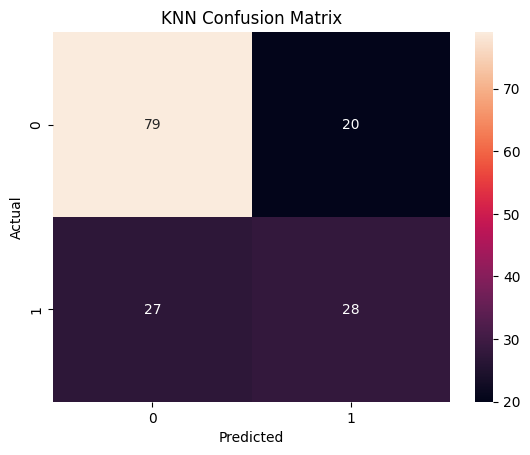

In [16]:
# Step 9: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

sns.heatmap(cm, annot=True, fmt="d")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN Confusion Matrix")
plt.show()

### Theory
These metrics measure model performance. Accuracy is the proportion correct, error rate is the proportion incorrect, precision measures positive predictions, and recall measures detected positive cases.

In [17]:
# Step 10: Calculate Evaluation Metrics
accuracy = accuracy_score(y_test, y_pred)
error_rate = 1 - accuracy
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)

print("Accuracy:", round(accuracy, 4))
print("Error Rate:", round(error_rate, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))

Accuracy: 0.6948
Error Rate: 0.3052
Precision: 0.5833
Recall: 0.5091


### Theory
The classification report displays precision, recall, F1-score, and the number of test samples for each class.

In [18]:
# Step 11: Classification Report
print(classification_report(y_test, y_pred, target_names=["No Diabetes", "Diabetes"], zero_division=0))

              precision    recall  f1-score   support

 No Diabetes       0.75      0.80      0.77        99
    Diabetes       0.58      0.51      0.54        55

    accuracy                           0.69       154
   macro avg       0.66      0.65      0.66       154
weighted avg       0.69      0.69      0.69       154



### Theory
This cell places the four evaluation metrics into a table. The Percentage column displays each metric on a 0–100 scale.

In [19]:
# Step 12: Display Metrics in a Table
results = pd.DataFrame({
    "Metric": ["Accuracy", "Error Rate", "Precision", "Recall"],
    "Value": [accuracy, error_rate, precision, recall]
})

results["Percentage"] = results["Value"] * 100
results

,Metric,Value,Percentage
0,Accuracy,0.694805,69.480519
1,Error Rate,0.305195,30.519481
2,Precision,0.583333,58.333333
3,Recall,0.509091,50.909091


## Conclusion

The K-Nearest Neighbors algorithm was successfully implemented on the diabetes dataset. The data was divided into training and testing sets and standardized before applying KNN. The model was evaluated using confusion matrix, accuracy, error rate, precision, and recall.

### Viva Point
KNN is a distance-based algorithm, so feature scaling is important. A larger value of K generally makes the model less sensitive to individual data points, while a smaller K can make it more sensitive to noise.
